### BREAST CANCER ML PROJECT
### DATA CLEANING + EDA PLOTS + MACHINE LEARNING + EVALUATION
### Target: Overall Survival Status

### 1. IMPORT LIBRARIES

In [1]:
# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score,
    f1_score, precision_score, recall_score
)


### 2. LOAD DATA

In [2]:
# Load the uploaded CSV, with fallback filenames for portability
from pathlib import Path

candidate_paths = [
    Path("Breast Cancer.csv"),
    Path("Breast Cancer(1).csv"),
    Path("/mnt/data/Breast Cancer(1).csv")
]
csv_path = next((p for p in candidate_paths if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError(
        "Could not find the dataset. Place 'Breast Cancer.csv' or "
        "'Breast Cancer(1).csv' in the notebook's working directory."
    )

df = pd.read_csv(csv_path)
print("Loaded:", csv_path)
print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())


Loaded: Breast Cancer(1).csv
Shape: (2509, 34)

First 5 rows:


,Patient ID,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Cancer Type Detailed,Cellularity,Chemotherapy,Pam50 + Claudin-low subtype,Cohort,ER status measured by IHC,ER Status,Neoplasm Histologic Grade,HER2 status measured by SNP6,HER2 Status,Tumor Other Histologic Subtype,Hormone Therapy,Inferred Menopausal State,Integrative Cluster,Primary Tumor Laterality,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Oncotree Code,Overall Survival (Months),Overall Survival Status,PR Status,Radio Therapy,Relapse Free Status (Months),Relapse Free Status,Sex,3-Gene classifier subtype,Tumor Size,Tumor Stage,Patient's Vital Status
0,MB-0000,75.65,Mastectomy,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,No,claudin-low,1.0,Positve,Positive,3.0,Neutral,Negative,Ductal/NST,Yes,Post,4ER+,Right,10.0,NaN,6.044,IDC,140.500000,Living,Negative,Yes,138.65,Not Recurred,Female,ER-/HER2-,22.0,2.0,Living
1,MB-0002,43.19,Breast Conserving,Breast Cancer,Breast Invasive Ductal Carcinoma,High,No,LumA,1.0,Positve,Positive,3.0,Neutral,Negative,Ductal/NST,Yes,Pre,4ER+,Right,0.0,2.0,4.020,IDC,84.633333,Living,Positive,Yes,83.52,Not Recurred,Female,ER+/HER2- High Prolif,10.0,1.0,Living
2,MB-0005,48.87,Mastectomy,Breast Cancer,Breast Invasive Ductal Carcinoma,High,Yes,LumB,1.0,Positve,Positive,2.0,Neutral,Negative,Ductal/NST,Yes,Pre,3,Right,1.0,2.0,4.030,IDC,163.700000,Deceased,Positive,No,151.28,Recurred,Female,NaN,15.0,2.0,Died of Disease
3,MB-0006,47.68,Mastectomy,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,Yes,LumB,1.0,Positve,Positive,2.0,Neutral,Negative,Mixed,Yes,Pre,9,Right,3.0,1.0,4.050,MDLC,164.933333,Living,Positive,Yes,162.76,Not Recurred,Female,NaN,25.0,2.0,Living
4,MB-0008,76.97,Mastectomy,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,Yes,LumB,1.0,Positve,Positive,3.0,Neutral,Negative,Mixed,Yes,Post,9,Right,8.0,2.0,6.080,MDLC,41.366667,Deceased,Positive,Yes,18.55,Recurred,Female,ER+/HER2- High Prolif,40.0,2.0,Died of Disease


### 3. BASIC DATA INFORMATION

In [3]:
print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isna().sum().sort_values(ascending=False))

print("\nMissing Percentage:")
print(
    (df.isna().mean() * 100)
    .sort_values(ascending=False)
)

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Data Types:
Patient ID                         object
Age at Diagnosis                  float64
Type of Breast Surgery             object
Cancer Type                        object
Cancer Type Detailed               object
Cellularity                        object
Chemotherapy                       object
Pam50 + Claudin-low subtype        object
Cohort                            float64
ER status measured by IHC          object
ER Status                          object
Neoplasm Histologic Grade         float64
HER2 status measured by SNP6       object
HER2 Status                        object
Tumor Other Histologic Subtype     object
Hormone Therapy                    object
Inferred Menopausal State          object
Integrative Cluster                object
Primary Tumor Laterality           object
Lymph nodes examined positive     float64
Mutation Count                    float64
Nottingham prognostic index       float64
Oncotree Code                      object
Overall Survival (Mon

### 4. REMOVE DUPLICATES

In [4]:
df = df.drop_duplicates().reset_index(drop=True)

### 5. CLEAN CATEGORICAL VALUES

In [5]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

### 6. CONVERT COMMON MISSING VALUES TO NaN

In [6]:
missing_values = [
    "",
    " ",
    "NA",
    "N/A",
    "na",
    "n/a",
    "None",
    "none",
    "NULL",
    "null",
    "?",
    "-"
]

df = df.replace(missing_values, np.nan)

### 7. PLOT 1 — MISSING VALUES

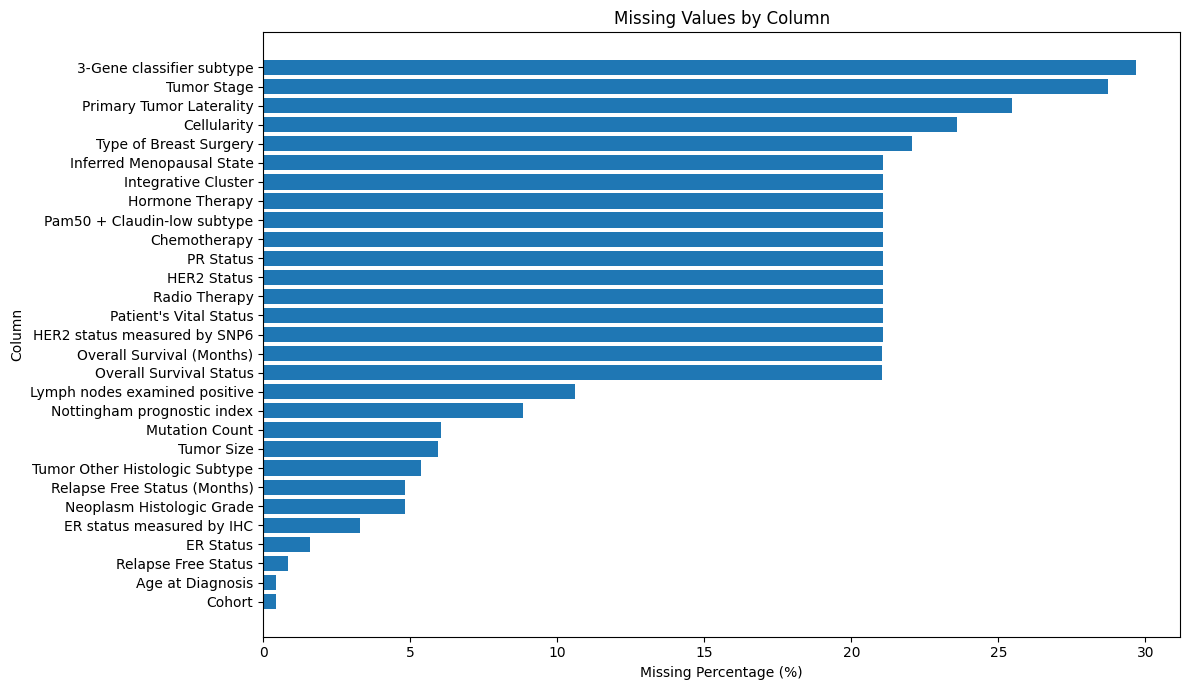

In [7]:
missing_percentage = (df.isna().mean() * 100).sort_values(ascending=False)
missing_percentage = missing_percentage[missing_percentage > 0]

if not missing_percentage.empty:
    plt.figure(figsize=(12, 7))
    plt.barh(missing_percentage.index.astype(str), missing_percentage.values)
    plt.gca().invert_yaxis()
    plt.title("Missing Values by Column")
    plt.xlabel("Missing Percentage (%)")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")


### 8. TARGET VARIABLE

In [8]:
target = "Overall Survival Status"

print("Target distribution, including missing labels:")
print(df[target].value_counts(dropna=False))


Target distribution, including missing labels:
Overall Survival Status
Deceased    1144
Living       837
NaN          528
Name: count, dtype: int64


### 9. PLOT 2 — TARGET DISTRIBUTION

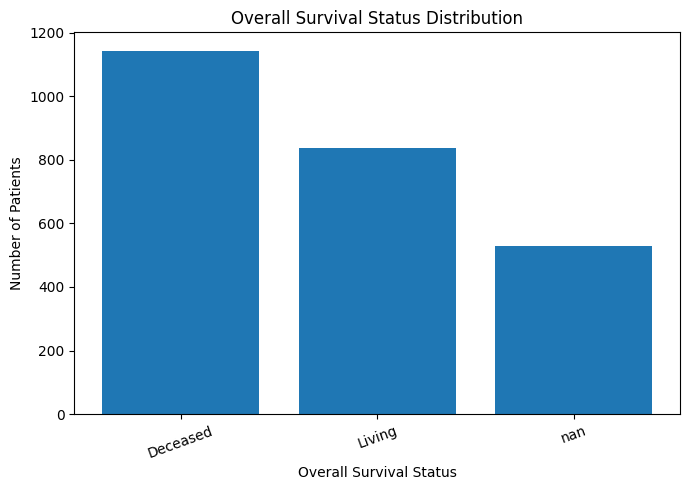

In [9]:
target_counts = df[target].value_counts(dropna=False)
plt.figure(figsize=(7, 5))
plt.bar(target_counts.index.astype(str), target_counts.values)
plt.title("Overall Survival Status Distribution")
plt.xlabel("Overall Survival Status")
plt.ylabel("Number of Patients")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### 10. REMOVE ROWS WHERE TARGET IS MISSING

In [10]:
# Remove rows without a known target label. These rows cannot be used for supervised learning.
df = df.dropna(subset=[target]).copy()
print("Rows with observed target:", len(df))


Rows with observed target: 1981


### 11. DEFINE THE PREDICTION TASK AND PREPARE FEATURES

We treat this as an exploratory **diagnosis-time binary classification** task. Columns describing survival duration, recurrence/follow-up outcomes, vital status, and post-diagnosis treatment are excluded because they would not be available at the intended prediction time. This is not a validated clinical model.


In [11]:
# Remove direct target leakage, future outcomes, identifiers, and post-diagnosis treatments.
# Treatment columns are excluded because this notebook's intended prediction point is diagnosis.
leakage_and_post_diagnosis_columns = [
    "Patient ID",
    "Patient_ID",
    "Patient ID Number",
    "ID",
    "id",
    "Patient's Vital Status",
    "Overall Survival (Months)",
    "Relapse Free Status",
    "Relapse Free Status (Months)",
    "Type of Breast Surgery",
    "Chemotherapy",
    "Hormone Therapy",
    "Radio Therapy",
    # Cohort is dataset/source metadata rather than a patient-level clinical predictor.
    "Cohort"
]

columns_to_remove = [c for c in leakage_and_post_diagnosis_columns if c in df.columns]
X = df.drop(columns=[target] + columns_to_remove, errors="ignore").copy()
y = df[target].copy()

print("Excluded columns:", columns_to_remove)
print("Target classes:", sorted(y.astype(str).unique().tolist()))
print("Feature matrix shape before engineering:", X.shape)


Excluded columns: ['Patient ID', "Patient's Vital Status", 'Overall Survival (Months)', 'Relapse Free Status', 'Relapse Free Status (Months)', 'Type of Breast Surgery', 'Chemotherapy', 'Hormone Therapy', 'Radio Therapy', 'Cohort']
Target classes: ['Deceased', 'Living']
Feature matrix shape before engineering: (1981, 23)


### 12. REMOVE IDENTIFIER COLUMNS

In [12]:
# Identifier removal is already handled in Section 11; this cell verifies no common ID column remains.
remaining_id_columns = [c for c in ["Patient ID", "Patient_ID", "Patient ID Number", "ID", "id"] if c in X.columns]
if remaining_id_columns:
    X = X.drop(columns=remaining_id_columns)
print("Identifier columns remaining:", remaining_id_columns)


Identifier columns remaining: []


### 13. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES

In [13]:
# Initial data types are shown here; final lists are recalculated after feature engineering.
print("Numerical columns before feature engineering:")
print(X.select_dtypes(include="number").columns.tolist())
print("\nCategorical columns before feature engineering:")
print(X.select_dtypes(include=["object", "category", "bool"]).columns.tolist())


Numerical columns before feature engineering:
['Age at Diagnosis', 'Neoplasm Histologic Grade', 'Lymph nodes examined positive', 'Mutation Count', 'Nottingham prognostic index', 'Tumor Size', 'Tumor Stage']

Categorical columns before feature engineering:
['Cancer Type', 'Cancer Type Detailed', 'Cellularity', 'Pam50 + Claudin-low subtype', 'ER status measured by IHC', 'ER Status', 'HER2 status measured by SNP6', 'HER2 Status', 'Tumor Other Histologic Subtype', 'Inferred Menopausal State', 'Integrative Cluster', 'Primary Tumor Laterality', 'Oncotree Code', 'PR Status', 'Sex', '3-Gene classifier subtype']


### 14. NUMERICAL DISTRIBUTION PLOTS

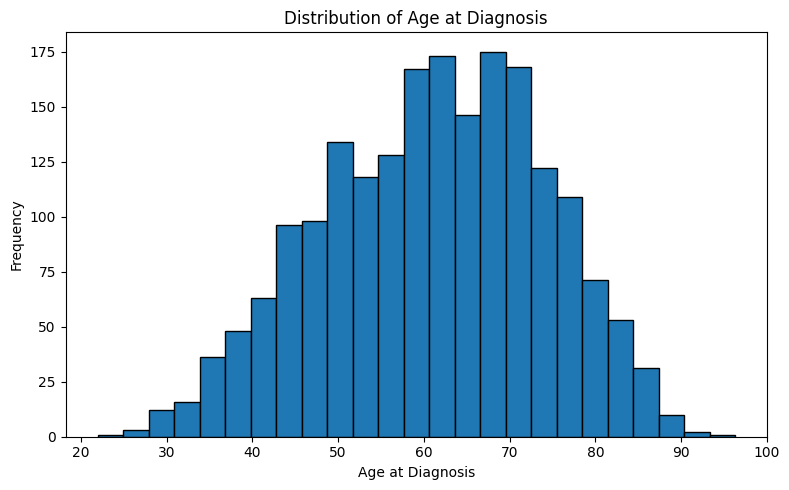

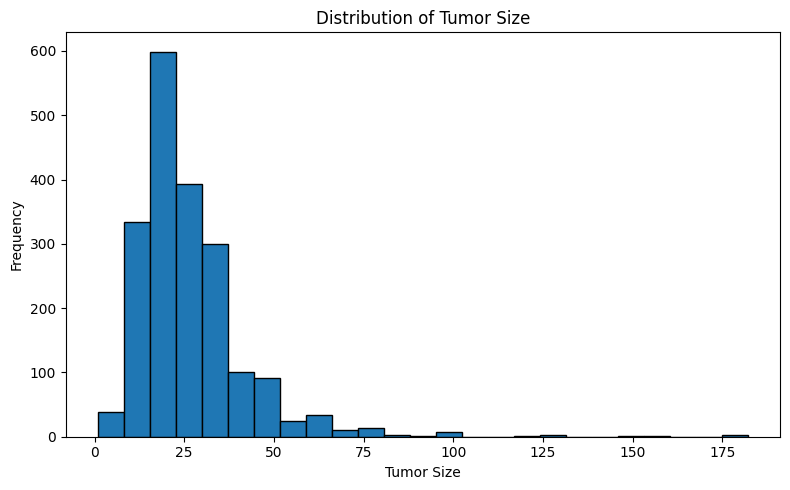

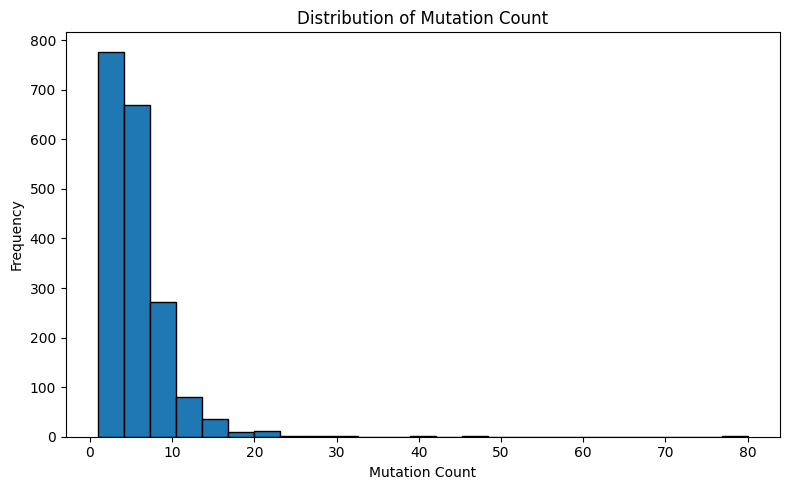

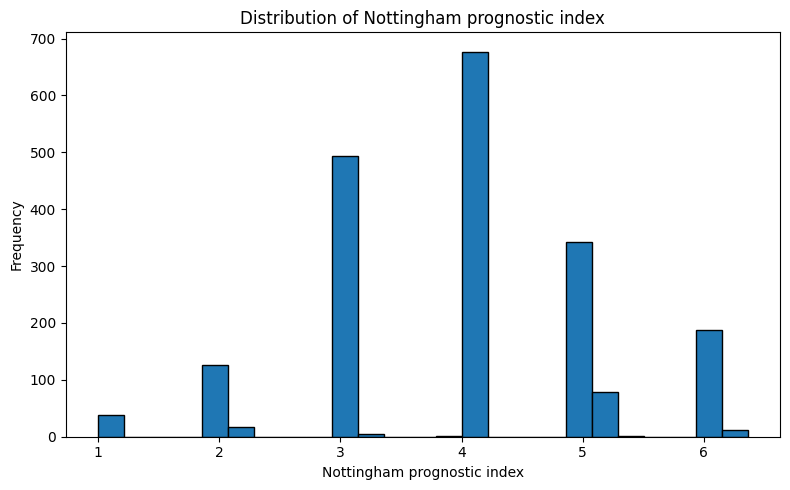

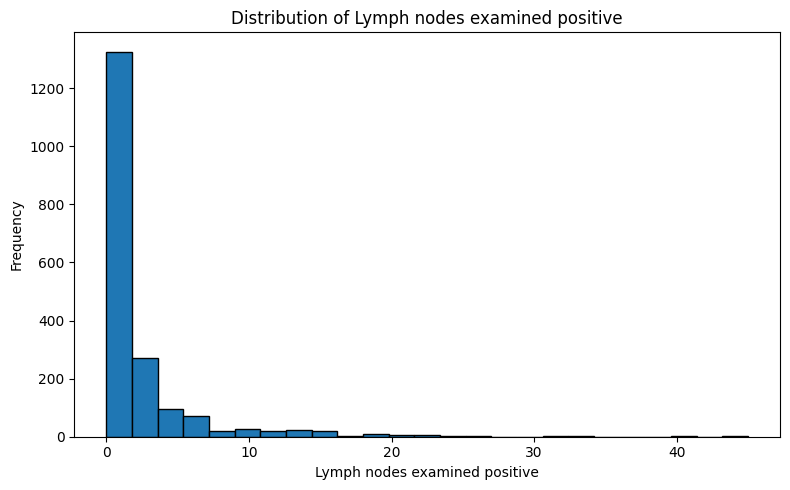

In [14]:
# Plot numeric predictor distributions with matplotlib for compatibility across seaborn versions.
important_numeric = [
    "Age at Diagnosis", "Tumor Size", "Mutation Count",
    "Nottingham prognostic index", "Lymph nodes examined positive"
]
important_numeric = [col for col in important_numeric if col in X.columns]
for col in important_numeric:
    values = pd.to_numeric(X[col], errors="coerce").dropna()
    plt.figure(figsize=(8, 5))
    plt.hist(values, bins=25, edgecolor="black")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


### 15. BOXPLOTS FOR OUTLIER DETECTION

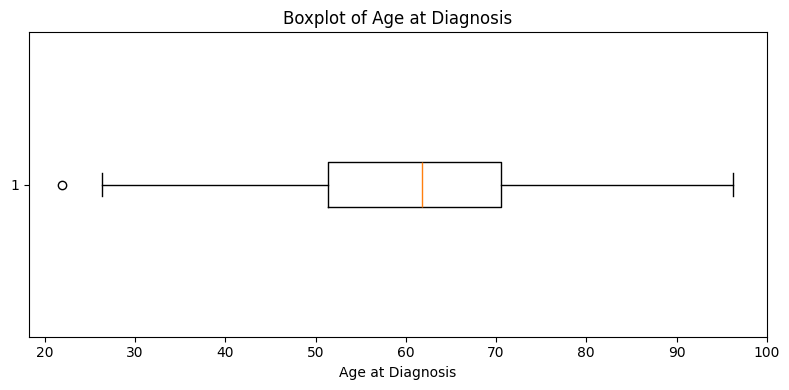

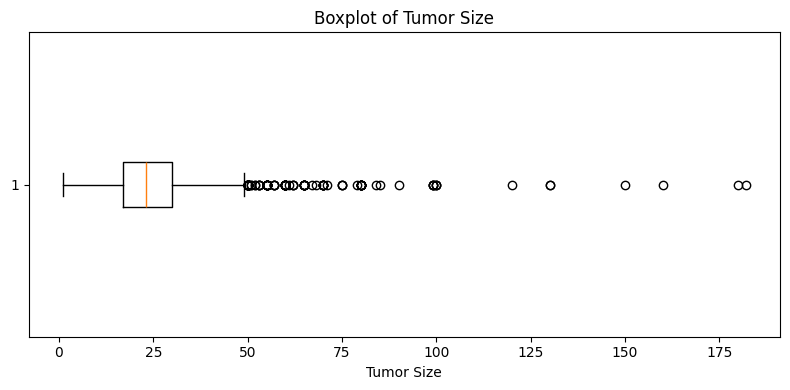

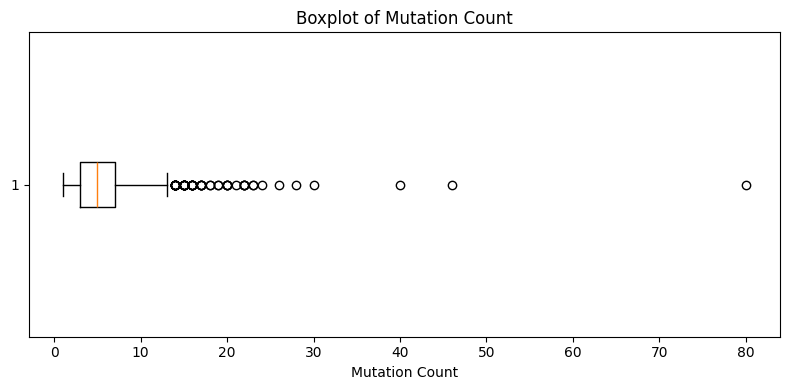

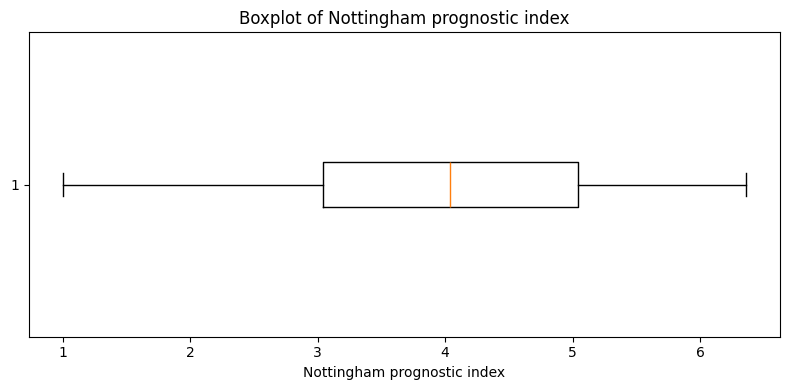

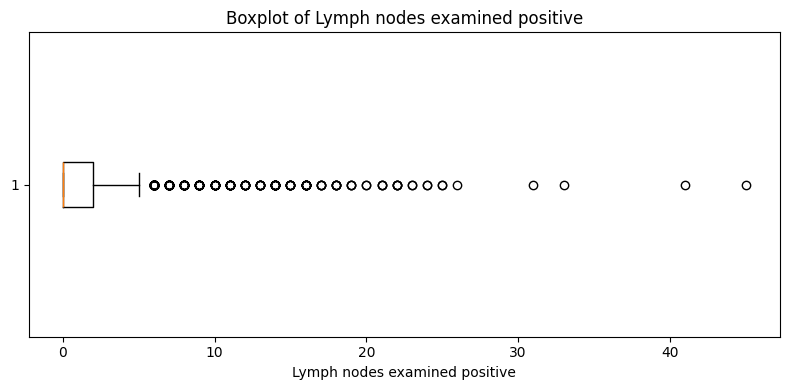

In [15]:
for col in important_numeric:
    values = pd.to_numeric(X[col], errors="coerce").dropna()
    plt.figure(figsize=(8, 4))
    plt.boxplot(values, vert=False)
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()


### 16. PLOT — AGE VS TUMOR SIZE

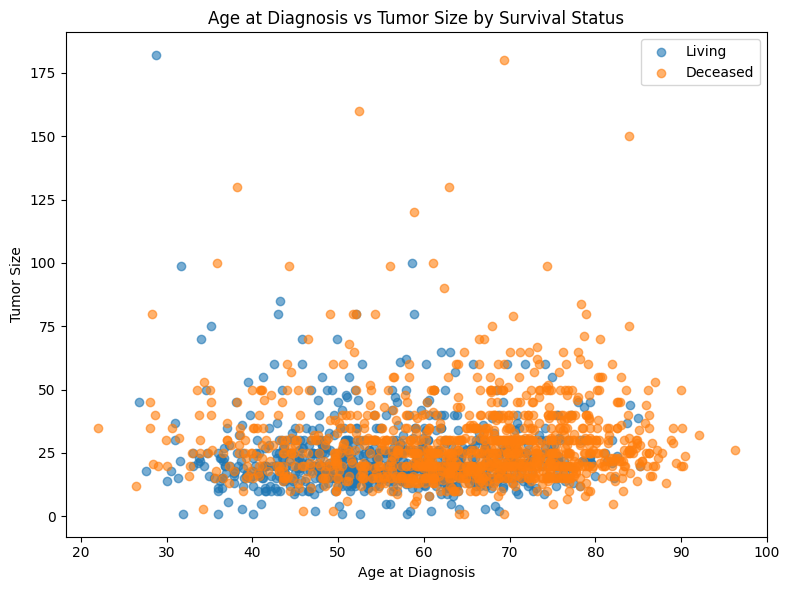

In [16]:
if "Age at Diagnosis" in X.columns and "Tumor Size" in X.columns:
    plot_data = pd.DataFrame({
        "Age": pd.to_numeric(X["Age at Diagnosis"], errors="coerce"),
        "Tumor Size": pd.to_numeric(X["Tumor Size"], errors="coerce"),
        "Target": y
    }).dropna()
    plt.figure(figsize=(8, 6))
    for label in plot_data["Target"].unique():
        subset = plot_data[plot_data["Target"] == label]
        plt.scatter(subset["Age"], subset["Tumor Size"], label=label, alpha=0.6)
    plt.title("Age at Diagnosis vs Tumor Size by Survival Status")
    plt.xlabel("Age at Diagnosis")
    plt.ylabel("Tumor Size")
    plt.legend()
    plt.tight_layout()
    plt.show()


### 17. CORRELATION HEATMAP

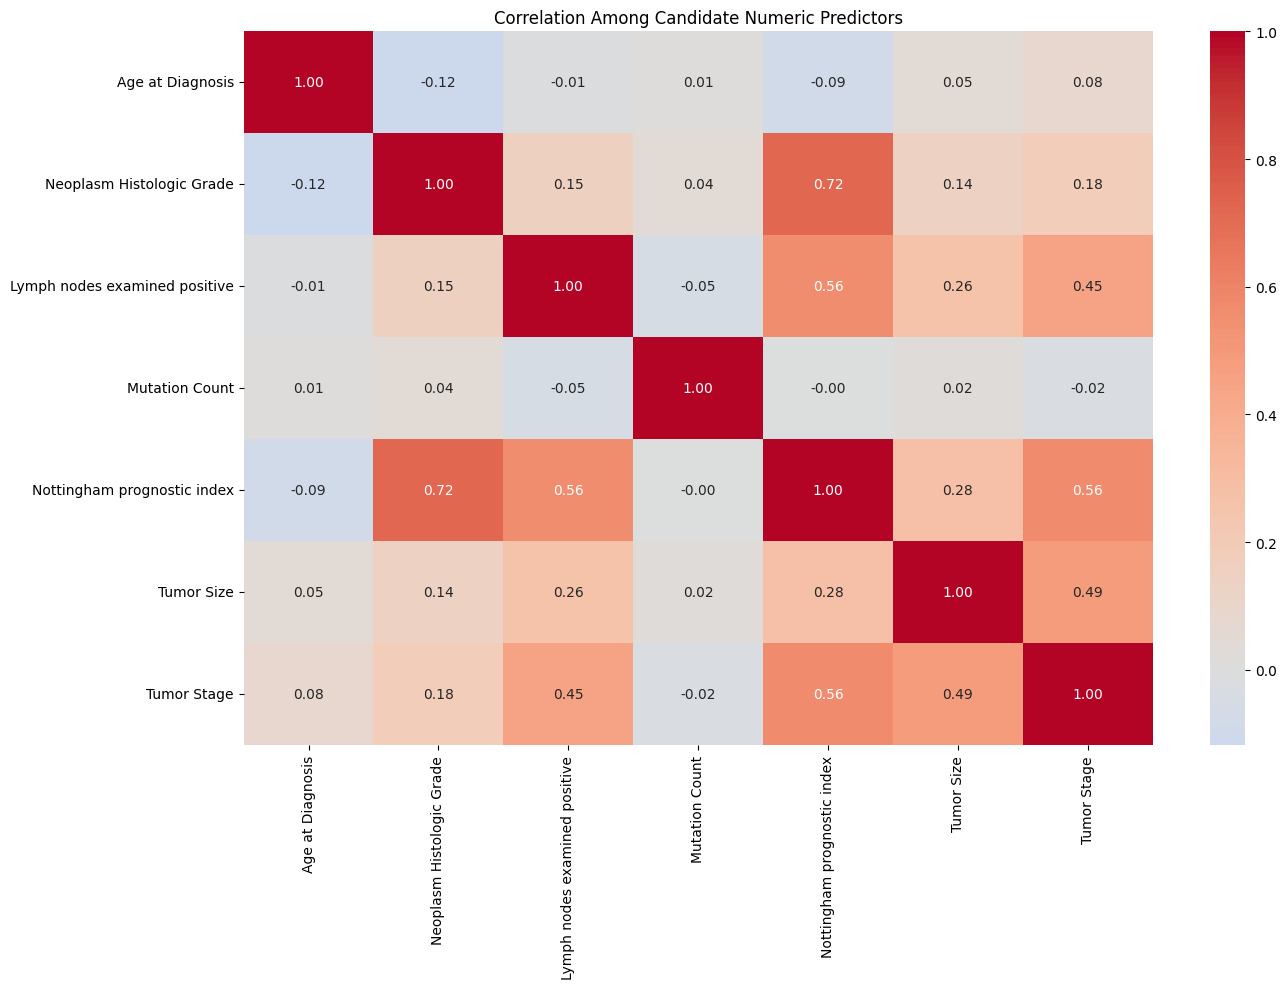

In [17]:
# Correlations among candidate numeric predictors only; target and future outcome fields are not included.
numeric_df = X.select_dtypes(include="number")
if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(14, 10))
    sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation Among Candidate Numeric Predictors")
    plt.tight_layout()
    plt.show()


### 18. FEATURE ENGINEERING AND TRAIN / TEST SPLIT

The transformations below are deterministic (not learned from the data). Imputation, scaling, and one-hot encoding are fitted later inside a pipeline using training folds only. The age bands are exploratory; compare models with and without them before making claims.


In [18]:
# Create interpretable transformations from variables plausibly available at diagnosis.
# Preserve original measurements as well as transformed versions.
if "Tumor Size" in X.columns:
    X["Log Tumor Size"] = np.log1p(pd.to_numeric(X["Tumor Size"], errors="coerce").clip(lower=0))

if "Lymph nodes examined positive" in X.columns:
    X["Log Positive Lymph Nodes"] = np.log1p(
        pd.to_numeric(X["Lymph nodes examined positive"], errors="coerce").clip(lower=0)
    )

if "Age at Diagnosis" in X.columns:
    age = pd.to_numeric(X["Age at Diagnosis"], errors="coerce")
    X["Age Group"] = pd.cut(
        age,
        bins=[0, 40, 50, 60, 70, np.inf],
        labels=["Under 40", "40-49", "50-59", "60-69", "70+"],
        right=False
    ).astype("object")

# Drop all-missing and constant predictors, which cannot provide useful split information.
all_missing = X.columns[X.isna().all()].tolist()
if all_missing:
    X = X.drop(columns=all_missing)

constant_columns = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
if constant_columns:
    X = X.drop(columns=constant_columns)

numeric_columns = X.select_dtypes(include=["number"]).columns.tolist()
categorical_columns = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Engineered feature matrix shape:", X.shape)
print("Added features:", [c for c in ["Log Tumor Size", "Log Positive Lymph Nodes", "Age Group"] if c in X.columns])
print("Removed all-missing columns:", all_missing)
print("Removed constant columns:", constant_columns)
print("Numeric feature count:", len(numeric_columns))
print("Categorical feature count:", len(categorical_columns))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Engineered feature matrix shape: (1981, 25)
Added features: ['Log Tumor Size', 'Log Positive Lymph Nodes', 'Age Group']
Removed all-missing columns: []
Removed constant columns: ['Sex']
Numeric feature count: 9
Categorical feature count: 16

Training shape: (1584, 25)
Testing shape: (397, 25)


### 19. NUMERICAL PREPROCESSING PIPELINE


In [19]:
numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

### 20. CATEGORICAL PREPROCESSING PIPELINE


In [20]:
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

### 21. COMBINED PREPROCESSOR


In [21]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_columns
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_columns
        )
    ]
)

### 22. LOGISTIC REGRESSION MODEL

In [22]:
logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced"
            )
        )
    ]
)

### 23. TRAIN LOGISTIC REGRESSION

In [23]:
logistic_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tra

### 24. LOGISTIC REGRESSION PREDICTION

In [24]:
y_pred_lr = logistic_model.predict(X_test)
positive_label = "Living"
if positive_label not in logistic_model.classes_:
    raise ValueError(f"Expected target class {positive_label!r}; found {logistic_model.classes_}")
positive_index_lr = list(logistic_model.classes_).index(positive_label)
y_prob_lr = logistic_model.predict_proba(X_test)[:, positive_index_lr]


### 25. LOGISTIC REGRESSION EVALUATION

In [25]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)
balanced_accuracy_lr = balanced_accuracy_score(y_test, y_pred_lr)
auc_lr = roc_auc_score((y_test == positive_label).astype(int), y_prob_lr)

print("\n==============================")
print("LOGISTIC REGRESSION — HOLDOUT TEST")
print("==============================")
print(f"Accuracy:          {accuracy_lr:.3f}")
print(f"Balanced accuracy: {balanced_accuracy_lr:.3f}")
print(f"ROC-AUC (Living):  {auc_lr:.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))



LOGISTIC REGRESSION — HOLDOUT TEST
Accuracy:          0.698
Balanced accuracy: 0.698
ROC-AUC (Living):  0.747

Classification report:
              precision    recall  f1-score   support

    Deceased       0.76      0.69      0.73       229
      Living       0.63      0.70      0.66       168

    accuracy                           0.70       397
   macro avg       0.69      0.70      0.69       397
weighted avg       0.70      0.70      0.70       397



### 26. CONFUSION MATRIX — LOGISTIC REGRESSION

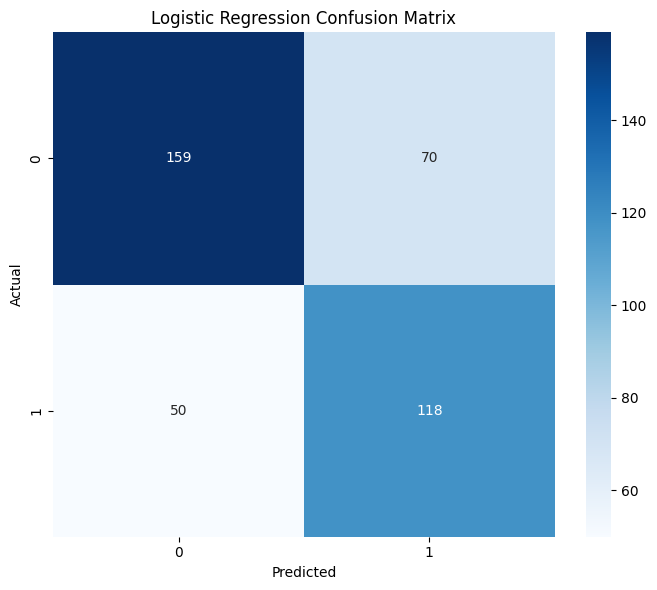

In [26]:
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

### 27. RANDOM FOREST MODEL

In [27]:
random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=None,
                min_samples_split=5,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

### 28. TRAIN RANDOM FOREST

In [28]:
random_forest_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tra

### 31. STRATIFIED CROSS-VALIDATION ON TRAINING DATA

In [29]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc",
    "f1_macro": "f1_macro"
}

cv_lr = cross_validate(logistic_model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
cv_rf = cross_validate(random_forest_model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

cv_results = pd.DataFrame([
    {"Model": "Logistic Regression", **{f"{m} mean": cv_lr[f"test_{m}"].mean() for m in scoring},
     **{f"{m} std": cv_lr[f"test_{m}"].std() for m in scoring}},
    {"Model": "Random Forest", **{f"{m} mean": cv_rf[f"test_{m}"].mean() for m in scoring},
     **{f"{m} std": cv_rf[f"test_{m}"].std() for m in scoring}}
])
print("5-fold cross-validation results on training data:")
display(cv_results.round(3))


5-fold cross-validation results on training data:


,Model,accuracy mean,balanced_accuracy mean,roc_auc mean,f1_macro mean,accuracy std,balanced_accuracy std,roc_auc std,f1_macro std
0,Logistic Regression,0.653,0.655,0.722,0.650,0.025,0.028,0.028,0.026
1,Random Forest,0.674,0.661,0.714,0.662,0.011,0.011,0.033,0.011


### 31. RANDOM FOREST PREDICTION

In [30]:
y_pred_rf = random_forest_model.predict(X_test)
positive_index_rf = list(random_forest_model.classes_).index(positive_label)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, positive_index_rf]


### 32. RANDOM FOREST EVALUATION

In [31]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
balanced_accuracy_rf = balanced_accuracy_score(y_test, y_pred_rf)
auc_rf = roc_auc_score((y_test == positive_label).astype(int), y_prob_rf)

print("\n==============================")
print("RANDOM FOREST — HOLDOUT TEST")
print("==============================")
print(f"Accuracy:          {accuracy_rf:.3f}")
print(f"Balanced accuracy: {balanced_accuracy_rf:.3f}")
print(f"ROC-AUC (Living):  {auc_rf:.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))



RANDOM FOREST — HOLDOUT TEST
Accuracy:          0.695
Balanced accuracy: 0.685
ROC-AUC (Living):  0.739

Classification report:
              precision    recall  f1-score   support

    Deceased       0.73      0.75      0.74       229
      Living       0.65      0.62      0.63       168

    accuracy                           0.70       397
   macro avg       0.69      0.69      0.69       397
weighted avg       0.69      0.70      0.69       397



### 33. CONFUSION MATRIX — RANDOM FOREST

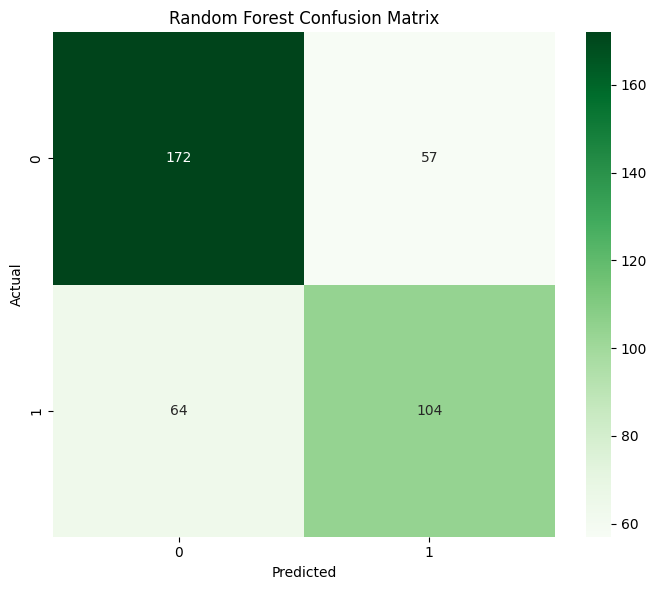

In [32]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

### 34. ROC CURVE

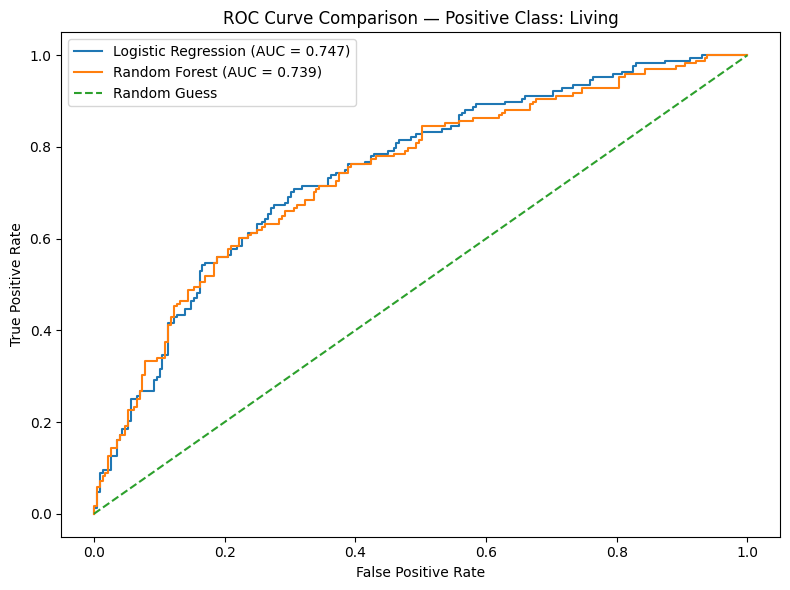

In [33]:
fpr_lr, tpr_lr, _ = roc_curve((y_test == positive_label).astype(int), y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve((y_test == positive_label).astype(int), y_prob_rf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")
plt.title("ROC Curve Comparison — Positive Class: Living")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()


### 35. MODEL COMPARISON

In [34]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy_lr, accuracy_rf],
    "Balanced Accuracy": [balanced_accuracy_lr, balanced_accuracy_rf],
    "ROC_AUC_Living": [auc_lr, auc_rf],
    "F1_macro": [
        f1_score(y_test, y_pred_lr, average="macro", zero_division=0),
        f1_score(y_test, y_pred_rf, average="macro", zero_division=0)
    ]
})
print("\nHOLDOUT MODEL COMPARISON")
display(results)



HOLDOUT MODEL COMPARISON


,Model,Accuracy,Balanced Accuracy,ROC_AUC_Living,F1_macro
0,Logistic Regression,0.697733,0.698352,0.747219,0.694474
1,Random Forest,0.695214,0.685070,0.739265,0.686002


### 36. MODEL COMPARISON PLOT

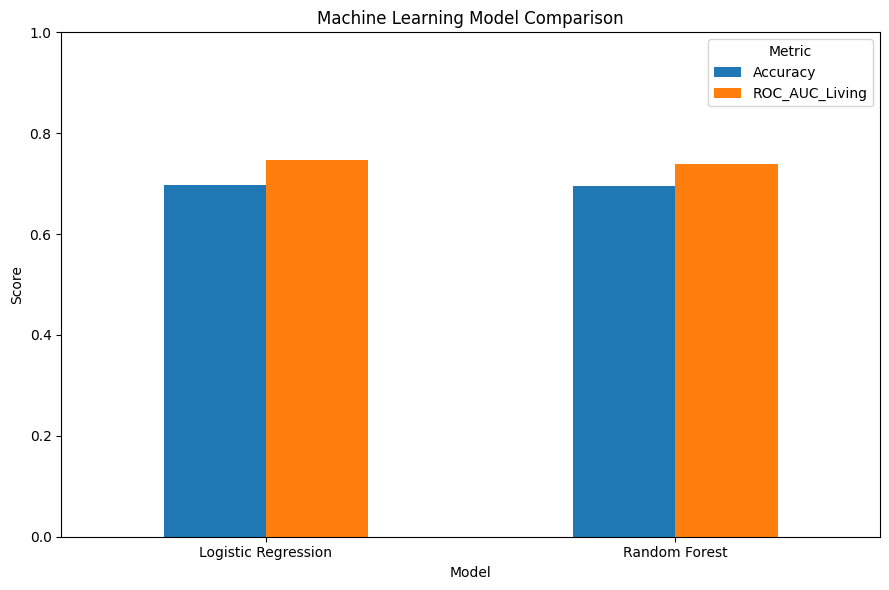

In [35]:
results_melted = results.melt(
    id_vars="Model",
    value_vars=["Accuracy", "ROC_AUC_Living"],
    var_name="Metric",
    value_name="Score"
)

pivot_results = results_melted.pivot(index="Model", columns="Metric", values="Score")
ax = pivot_results.plot(kind="bar", figsize=(9, 6))
ax.set_title("Machine Learning Model Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### 37. SAVE MODEL RESULTS

In [36]:
results.to_csv("model_comparison.csv", index=False)
print("Saved model_comparison.csv")


Saved model_comparison.csv


### 38. FINAL MODEL

In [37]:
# Choose by holdout ROC-AUC as a simple demonstration only.
# For rigorous model selection, choose using cross-validation on training data, then test once.
if auc_rf >= auc_lr:
    final_model = random_forest_model
    print("Selected demonstration model: Random Forest")
else:
    final_model = logistic_model
    print("Selected demonstration model: Logistic Regression")


Selected demonstration model: Logistic Regression


### 39. EXAMPLE PREDICTION

In [38]:
# Example prediction for one held-out row; this is a demonstration, not a clinical recommendation.
sample = X_test.iloc[[0]]
prediction = final_model.predict(sample)
probability = final_model.predict_proba(sample)[0]
class_probabilities = dict(zip(final_model.classes_, probability))

print("\nEXAMPLE HELD-OUT PREDICTION")
print("Actual label:", y_test.iloc[0])
print("Predicted label:", prediction[0])
print("Class probabilities:", class_probabilities)



EXAMPLE HELD-OUT PREDICTION
Actual label: Living
Predicted label: Living
Class probabilities: {'Deceased': np.float64(0.33056170250800343), 'Living': np.float64(0.6694382974919966)}
